In [ ]:
from google.colab import files

uploaded = files.upload()

Saving calibration_photos.zip to calibration_photos.zip


In [ ]:
import zipfile
from pathlib import Path

zip_path = "/content/calibration_photos.zip"
extract_dir = Path("/content/calibration_photos")

extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

images = sorted(
    p for p in extract_dir.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

print("Total calibration images:", len(images))

for i, image in enumerate(images, start=1):
    print(f"{i}. {image.name}")

Total calibration images: 26
1. WhatsApp Image 2026-11-04 at 21.22.46 (1).jpeg
2. WhatsApp Image 2026-11-04 at 21.22.46 (2).jpeg
3. WhatsApp Image 2026-11-04 at 21.22.46.jpeg
4. WhatsApp Image 2026-11-04 at 21.22.47 (1).jpeg
5. WhatsApp Image 2026-11-04 at 21.22.47 (2).jpeg
6. WhatsApp Image 2026-11-04 at 21.22.47.jpeg
7. WhatsApp Image 2026-11-04 at 21.22.48 (1).jpeg
8. WhatsApp Image 2026-11-04 at 21.22.48 (2).jpeg
9. WhatsApp Image 2026-11-04 at 21.22.48.jpeg
10. WhatsApp Image 2026-11-04 at 21.22.49 (1).jpeg
11. WhatsApp Image 2026-11-04 at 21.22.49.jpeg
12. WhatsApp Image 2026-11-04 at 21.22.50 (1).jpeg
13. WhatsApp Image 2026-11-04 at 21.22.50.jpeg
14. WhatsApp Image 2026-11-04 at 21.22.51 (1).jpeg
15. WhatsApp Image 2026-11-04 at 21.22.51 (2).jpeg
16. WhatsApp Image 2026-11-04 at 21.22.51.jpeg
17. WhatsApp Image 2026-11-04 at 21.22.52 (1).jpeg
18. WhatsApp Image 2026-11-04 at 21.22.52.jpeg
19. WhatsApp Image 2026-11-04 at 21.22.53 (1).jpeg
20. WhatsApp Image 2026-11-04 at 21.22.

In [ ]:
import cv2
import numpy as np

# Our checkerboard has 9 × 7 INNER corners
CHECKERBOARD = (9, 7)

successful_images = []
failed_images = []
detected_corners = {}

for image_path in images:
    img = cv2.imread(str(image_path))

    if img is None:
        failed_images.append(image_path.name)
        print(f"FAILED to read: {image_path.name}")
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Detect checkerboard corners
    found, corners = cv2.findChessboardCornersSB(
        gray,
        CHECKERBOARD,
        flags=cv2.CALIB_CB_EXHAUSTIVE
    )

    if found:
        successful_images.append(image_path)
        detected_corners[image_path.name] = corners
        print(f"SUCCESS: {image_path.name}")
    else:
        failed_images.append(image_path.name)
        print(f"FAILED: {image_path.name}")

print("\n" + "=" * 40)
print("CALIBRATION IMAGE SUMMARY")
print("=" * 40)
print("Total images:", len(images))
print("Successfully detected:", len(successful_images))
print("Failed detection:", len(failed_images))
print("Minimum required:", 20)

if len(successful_images) >= 20:
    print("\nPASS: Enough images for calibration.")
else:
    print("\nWARNING: Fewer than 20 usable images.")

SUCCESS: WhatsApp Image 2026-11-04 at 21.22.46 (1).jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.46 (2).jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.46.jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.47 (1).jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.47 (2).jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.47.jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.48 (1).jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.48 (2).jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.48.jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.49 (1).jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.49.jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.50 (1).jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.50.jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.51 (1).jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.51 (2).jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.51.jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.52 (1).jpeg
SUCCESS: WhatsApp Image 2026-11-04 at 21.22.52.jpeg
SUCCESS: WhatsApp Im

In [ ]:
import cv2
import numpy as np

CHECKERBOARD = (9, 7)

# Prepare the checkerboard's 3D coordinates
# Square size = 1 arbitrary unit
objp = np.zeros(
    (CHECKERBOARD[0] * CHECKERBOARD[1], 3),
    dtype=np.float32
)

objp[:, :2] = np.mgrid[
    0:CHECKERBOARD[0],
    0:CHECKERBOARD[1]
].T.reshape(-1, 2)

object_points = []
image_points = []

image_size = None

for image_path in successful_images:

    image = cv2.imread(str(image_path))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    current_size = (gray.shape[1], gray.shape[0])

    if image_size is None:
        image_size = current_size

    if current_size != image_size:
        raise ValueError("Calibration image sizes differ!")

    object_points.append(objp.copy())
    image_points.append(
        detected_corners[image_path.name].astype(np.float32)
    )

# Calibrate camera
rms, camera_matrix, dist_coeffs, rvecs, tvecs = (
    cv2.calibrateCamera(
        object_points,
        image_points,
        image_size,
        None,
        None
    )
)

print("=" * 50)
print("CAMERA CALIBRATION RESULTS")
print("=" * 50)

print("\nImages used:", len(object_points))
print("Image resolution:", image_size)

print("\nCamera Matrix:")
print(camera_matrix)

print("\nDistortion Coefficients:")
print(dist_coeffs)

print("\nOpenCV RMS Reprojection Error:")
print(rms, "pixels")

# Calculate per-image reprojection errors
per_image_errors = []

for i in range(len(object_points)):

    projected, _ = cv2.projectPoints(
        object_points[i],
        rvecs[i],
        tvecs[i],
        camera_matrix,
        dist_coeffs
    )

    error = np.sqrt(
        np.mean(
            np.sum(
                (
                    image_points[i].reshape(-1, 2)
                    - projected.reshape(-1, 2)
                ) ** 2,
                axis=1
            )
        )
    )

    per_image_errors.append(error)

print("\nPer-image RMS errors:")

for path, error in zip(successful_images, per_image_errors):
    print(f"{path.name}: {error:.4f} px")

print("\nMean per-image RMS error:",
      round(float(np.mean(per_image_errors)), 4), "px")

print("Worst per-image RMS error:",
      round(float(np.max(per_image_errors)), 4), "px")

# Save calibration parameters
np.savez(
    "/content/camera_calibration.npz",
    camera_matrix=camera_matrix,
    dist_coeffs=dist_coeffs,
    image_width=image_size[0],
    image_height=image_size[1],
    rms_error=rms,
    square_size_units=1.0,
    successful_image_count=len(object_points)
)

print("\nSaved: /content/camera_calibration.npz")

CAMERA CALIBRATION RESULTS

Images used: 25
Image resolution: (1600, 720)

Camera Matrix:
[[1.25364748e+03 0.00000000e+00 8.06113766e+02]
 [0.00000000e+00 1.25703476e+03 3.63583450e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Distortion Coefficients:
[[ 2.20524447e-01 -9.92969332e-01 -3.37755594e-04  6.57559182e-04
   1.95894251e+00]]

OpenCV RMS Reprojection Error:
0.519165150079247 pixels

Per-image RMS errors:
WhatsApp Image 2026-11-04 at 21.22.46 (1).jpeg: 0.2480 px
WhatsApp Image 2026-11-04 at 21.22.46 (2).jpeg: 0.1532 px
WhatsApp Image 2026-11-04 at 21.22.46.jpeg: 0.2073 px
WhatsApp Image 2026-11-04 at 21.22.47 (1).jpeg: 0.1931 px
WhatsApp Image 2026-11-04 at 21.22.47 (2).jpeg: 0.1969 px
WhatsApp Image 2026-11-04 at 21.22.47.jpeg: 0.8087 px
WhatsApp Image 2026-11-04 at 21.22.48 (1).jpeg: 0.1939 px
WhatsApp Image 2026-11-04 at 21.22.48 (2).jpeg: 0.1994 px
WhatsApp Image 2026-11-04 at 21.22.48.jpeg: 0.2116 px
WhatsApp Image 2026-11-04 at 21.22.49 (1).jpeg: 0.2131 px
Whats

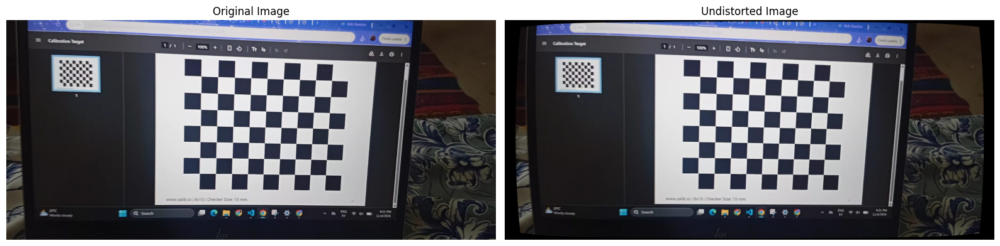

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Select one calibration image
image_path = successful_images[0]

# Load original image
original = cv2.imread(str(image_path))

# Apply camera undistortion
undistorted = cv2.undistort(
    original,
    camera_matrix,
    dist_coeffs
)

# Convert BGR to RGB for display
original_rgb = cv2.cvtColor(
    original,
    cv2.COLOR_BGR2RGB
)

undistorted_rgb = cv2.cvtColor(
    undistorted,
    cv2.COLOR_BGR2RGB
)

# Display comparison
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(undistorted_rgb)
plt.title("Undistorted Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

# Connect Google Drive
drive.mount("/content/drive")

# Create calibration directory
save_dir = Path(
    "/content/drive/MyDrive/MeasureIt/calibration"
)

save_dir.mkdir(parents=True, exist_ok=True)

# Copy calibration parameters
source = Path("/content/camera_calibration.npz")

destination = save_dir / "camera_calibration.npz"

shutil.copy2(source, destination)

print("Calibration saved successfully!")
print("Location:", destination)
print("File size:", destination.stat().st_size, "bytes")

Mounted at /content/drive
Calibration saved successfully!
Location: /content/drive/MyDrive/MeasureIt/calibration/camera_calibration.npz
File size: 1988 bytes


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving medicine_box_photos.zip to medicine_box_photos.zip


In [ ]:
import zipfile
from pathlib import Path
from collections import Counter
from PIL import Image

# Dataset paths
ZIP_PATH = Path("/content/medicine_box_photos.zip")
DATASET_DIR = Path("/content/medicine_box_dataset")

DATASET_DIR.mkdir(parents=True, exist_ok=True)

# Extract photographs
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATASET_DIR)

# Collect image files
medicine_images = sorted([
    p for p in DATASET_DIR.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

print("=" * 45)
print("MEDICINE BOX DATASET")
print("=" * 45)

print("Total images:", len(medicine_images))

# Check resolutions
resolutions = []

for image_path in medicine_images:
    with Image.open(image_path) as img:
        resolutions.append(img.size)

print("\nImage resolutions:")

for resolution, count in Counter(resolutions).items():
    print(f"{resolution}: {count} images")

# Check minimum requirement
if len(medicine_images) >= 70:
    print("\nPASS: Minimum dataset size achieved.")
else:
    print("\nWARNING: Fewer than 70 images.")

print("\nDataset folder:", DATASET_DIR)

MEDICINE BOX DATASET
Total images: 70

Image resolutions:
(720, 1600): 34 images
(1600, 720): 35 images
(1080, 1440): 1 images

PASS: Minimum dataset size achieved.

Dataset folder: /content/medicine_box_dataset


In [ ]:
import cv2
import numpy as np
import hashlib
from collections import defaultdict

def calculate_phash(image_path):
    """Compute a perceptual hash for an image."""
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read: {image_path}")

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    resized = cv2.resize(gray, (32, 32))

    dct = cv2.dct(np.float32(resized))
    low_frequency = dct[:8, :8]

    values = low_frequency.flatten()[1:]
    median = np.median(values)

    return values > median


def hash_distance(hash1, hash2):
    return int(np.count_nonzero(hash1 != hash2))


def file_sha256(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            sha.update(chunk)

    return sha.hexdigest()


# Calculate hashes
perceptual_hashes = {
    path.name: calculate_phash(path)
    for path in medicine_images
}

exact_hashes = defaultdict(list)

for path in medicine_images:
    exact_hashes[file_sha256(path)].append(path.name)

exact_duplicates = [
    group for group in exact_hashes.values()
    if len(group) > 1
]

print("=" * 50)
print("DUPLICATE IMAGE ANALYSIS")
print("=" * 50)

print("Total images:", len(medicine_images))
print("Exact duplicate groups:", len(exact_duplicates))

# Find visually similar pairs
similar_pairs = []

for i in range(len(medicine_images)):
    for j in range(i + 1, len(medicine_images)):

        name1 = medicine_images[i].name
        name2 = medicine_images[j].name

        distance = hash_distance(
            perceptual_hashes[name1],
            perceptual_hashes[name2]
        )

        if distance <= 6:
            similar_pairs.append((name1, name2, distance))

print("Potentially similar image pairs:", len(similar_pairs))

print("\nFirst 15 similar pairs:")

for name1, name2, distance in similar_pairs[:15]:
    print(f"{name1} <-> {name2}")
    print(f"Perceptual hash distance: {distance}\n")

print("\nAnalysis complete.")

DUPLICATE IMAGE ANALYSIS
Total images: 70
Exact duplicate groups: 0
Potentially similar image pairs: 27

First 15 similar pairs:
WhatsApp Image 2026-11-04 at 23.38.10.jpeg <-> WhatsApp Image 2026-11-04 at 23.38.11 (2).jpeg
Perceptual hash distance: 6

WhatsApp Image 2026-11-04 at 23.38.10.jpeg <-> WhatsApp Image 2026-11-04 at 23.38.12.jpeg
Perceptual hash distance: 6

WhatsApp Image 2026-11-04 at 23.38.11 (1).jpeg <-> WhatsApp Image 2026-11-04 at 23.38.11 (2).jpeg
Perceptual hash distance: 4

WhatsApp Image 2026-11-04 at 23.38.11 (1).jpeg <-> WhatsApp Image 2026-11-04 at 23.38.12.jpeg
Perceptual hash distance: 4

WhatsApp Image 2026-11-04 at 23.38.11 (1).jpeg <-> WhatsApp Image 2026-11-04 at 23.38.46 (1).jpeg
Perceptual hash distance: 4

WhatsApp Image 2026-11-04 at 23.38.11 (1).jpeg <-> WhatsApp Image 2026-11-04 at 23.38.46 (2).jpeg
Perceptual hash distance: 6

WhatsApp Image 2026-11-04 at 23.38.11 (2).jpeg <-> WhatsApp Image 2026-11-04 at 23.38.12.jpeg
Perceptual hash distance: 4

Wh

In [ ]:
from collections import defaultdict

# Each image initially belongs to its own group
parent = {
    path.name: path.name
    for path in medicine_images
}

def find(name):
    if parent[name] != name:
        parent[name] = find(parent[name])
    return parent[name]

def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a

# Put potentially similar images together
for name1, name2, distance in similar_pairs:
    union(name1, name2)

# Collect groups
groups = defaultdict(list)

for path in medicine_images:
    groups[find(path.name)].append(path.name)

image_groups = list(groups.values())

# Sort groups by size
image_groups.sort(key=len, reverse=True)

print("=" * 45)
print("IMAGE SIMILARITY GROUPS")
print("=" * 45)

print("Total images:", len(medicine_images))
print("Total groups:", len(image_groups))
print("Largest group size:", max(map(len, image_groups)))

print("\nGroups containing multiple images:")

for i, group in enumerate(image_groups, start=1):
    if len(group) > 1:
        print(f"\nGroup {i}: {len(group)} images")

        for filename in group:
            print(" -", filename)

print("\nGrouping complete.")

IMAGE SIMILARITY GROUPS
Total images: 70
Total groups: 53
Largest group size: 7

Groups containing multiple images:

Group 1: 7 images
 - WhatsApp Image 2026-11-04 at 23.38.10.jpeg
 - WhatsApp Image 2026-11-04 at 23.38.11 (1).jpeg
 - WhatsApp Image 2026-11-04 at 23.38.11 (2).jpeg
 - WhatsApp Image 2026-11-04 at 23.38.12.jpeg
 - WhatsApp Image 2026-11-04 at 23.38.13.jpeg
 - WhatsApp Image 2026-11-04 at 23.38.46 (1).jpeg
 - WhatsApp Image 2026-11-04 at 23.38.46 (2).jpeg

Group 2: 3 images
 - WhatsApp Image 2026-11-04 at 23.38.15 (1).jpeg
 - WhatsApp Image 2026-11-04 at 23.38.15.jpeg
 - WhatsApp Image 2026-11-04 at 23.38.16.jpeg

Group 3: 3 images
 - WhatsApp Image 2026-11-04 at 23.38.26.jpeg
 - WhatsApp Image 2026-11-04 at 23.38.27 (1).jpeg
 - WhatsApp Image 2026-11-04 at 23.38.27.jpeg

Group 4: 3 images
 - WhatsApp Image 2026-11-04 at 23.38.33 (1).jpeg
 - WhatsApp Image 2026-11-04 at 23.38.34 (1).jpeg
 - WhatsApp Image 2026-11-04 at 23.38.34.jpeg

Group 5: 2 images
 - WhatsApp Image 202

In [ ]:
import random
from pathlib import Path

SEED = 42
random.seed(SEED)

# Separate multi-image and single-image groups
multi_image_groups = [
    group for group in image_groups
    if len(group) > 1
]

single_image_groups = [
    group for group in image_groups
    if len(group) == 1
]

# Keep detected near-duplicate groups in training
train_files = [
    filename
    for group in multi_image_groups
    for filename in group
]

# Shuffle unique single-image groups reproducibly
single_files = [
    group[0]
    for group in single_image_groups
]

random.shuffle(single_files)

# Allocate unique images to test and validation
test_files = single_files[:7]
val_files = single_files[7:21]

# Remaining unique images go into training
train_files.extend(single_files[21:])

# Sort filenames for stable output
train_files = sorted(train_files)
val_files = sorted(val_files)
test_files = sorted(test_files)

# Validate sizes
assert len(train_files) == 49
assert len(val_files) == 14
assert len(test_files) == 7

# Check for overlap
assert not set(train_files) & set(val_files)
assert not set(train_files) & set(test_files)
assert not set(val_files) & set(test_files)

# Verify all photographs are included
all_split_files = train_files + val_files + test_files

assert len(set(all_split_files)) == 70
assert set(all_split_files) == {
    path.name for path in medicine_images
}

# Save split files
SPLIT_DIR = Path("/content/medicine_box_splits")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

for name, filenames in [
    ("train.txt", train_files),
    ("val.txt", val_files),
    ("test.txt", test_files)
]:
    (SPLIT_DIR / name).write_text(
        "\n".join(filenames) + "\n",
        encoding="utf-8"
    )

print("=" * 45)
print("FIXED DATASET SPLIT")
print("=" * 45)

print("Random seed:", SEED)
print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("Test images:", len(test_files))

print("\nNo overlap between splits: PASS")
print("All 70 images accounted for: PASS")

print("\nSplit files saved to:", SPLIT_DIR)

FIXED DATASET SPLIT
Random seed: 42
Training images: 49
Validation images: 14
Test images: 7

No overlap between splits: PASS
All 70 images accounted for: PASS

Split files saved to: /content/medicine_box_splits


In [ ]:
import zipfile
from google.colab import files
from pathlib import Path

split_dir = Path("/content/medicine_box_splits")
zip_path = Path("/content/medicine_box_splits.zip")

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for filename in ["train.txt", "val.txt", "test.txt"]:
        file_path = split_dir / filename

        assert file_path.exists(), f"Missing: {filename}"

        zipf.write(
            file_path,
            arcname=f"dataset/splits/{filename}"
        )

print("Split archive created successfully!")
print("File:", zip_path)

files.download(str(zip_path))

Split archive created successfully!
File: /content/medicine_box_splits.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Candidate object detected.
Polygon points: 4


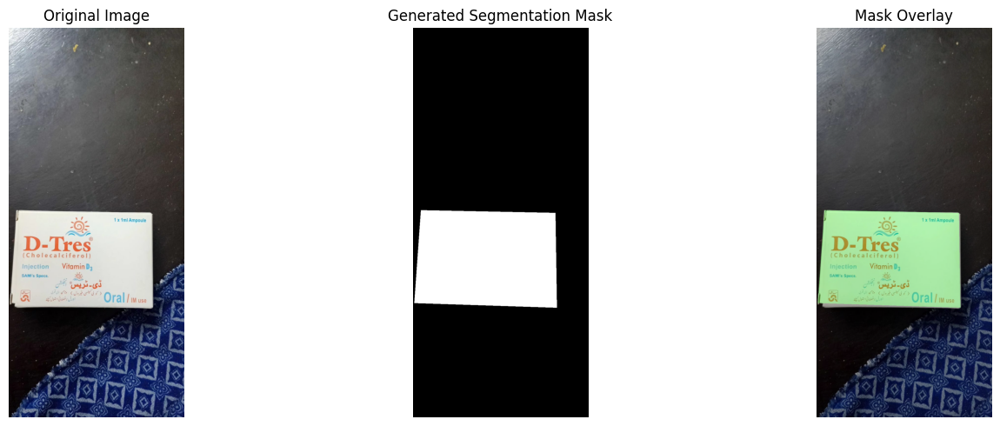

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Select the first medicine-box photograph
image_path = medicine_images[0]

image = cv2.imread(str(image_path))

if image is None:
    raise ValueError("Image could not be loaded")

# Convert to HSV colour space
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Identify bright, low-saturation areas
# The medicine box has a mostly white front face
lower_white = np.array([0, 0, 125])
upper_white = np.array([179, 90, 255])

white_mask = cv2.inRange(
    hsv,
    lower_white,
    upper_white
)

# Remove noise and close small gaps
kernel = np.ones((7, 7), np.uint8)

cleaned = cv2.morphologyEx(
    white_mask,
    cv2.MORPH_CLOSE,
    kernel
)

cleaned = cv2.morphologyEx(
    cleaned,
    cv2.MORPH_OPEN,
    kernel
)

# Find candidate object contours
contours, _ = cv2.findContours(
    cleaned,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

height, width = image.shape[:2]
image_area = height * width

candidates = []

for contour in contours:

    area = cv2.contourArea(contour)

    # Reject tiny regions and excessively large regions
    if not (0.005 * image_area < area < 0.5 * image_area):
        continue

    x, y, w, h = cv2.boundingRect(contour)

    aspect_ratio = max(w, h) / max(min(w, h), 1)

    if aspect_ratio > 3.5:
        continue

    rectangularity = area / max(w * h, 1)

    if rectangularity < 0.60:
        continue

    candidates.append((area, contour))

# Create output mask
mask = np.zeros(image.shape[:2], dtype=np.uint8)

if candidates:

    # Select the largest qualifying candidate
    _, best_contour = max(
        candidates,
        key=lambda item: item[0]
    )

    # Approximate the outer boundary
    perimeter = cv2.arcLength(best_contour, True)

    polygon = cv2.approxPolyDP(
        best_contour,
        0.02 * perimeter,
        True
    )

    cv2.drawContours(
        mask,
        [polygon],
        -1,
        255,
        thickness=cv2.FILLED
    )

    print("Candidate object detected.")
    print("Polygon points:", len(polygon))

else:
    print("No suitable object candidate detected.")

# Create overlay
overlay = image.copy()

coloured = np.zeros_like(image)
coloured[:, :, 1] = mask

overlay = cv2.addWeighted(
    image,
    0.75,
    coloured,
    0.25,
    0
)

# Display results
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Generated Segmentation Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Mask Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

AUTOMATIC MASK GENERATION
Total images: 70
Masks generated: 70
Detection failures: 27

Images requiring correction:
- WhatsApp Image 2026-11-04 at 23.38.18 (1).jpeg
- WhatsApp Image 2026-11-04 at 23.38.19.jpeg
- WhatsApp Image 2026-11-04 at 23.38.20 (1).jpeg
- WhatsApp Image 2026-11-04 at 23.38.20.jpeg
- WhatsApp Image 2026-11-04 at 23.38.22 (1).jpeg
- WhatsApp Image 2026-11-04 at 23.38.22.jpeg
- WhatsApp Image 2026-11-04 at 23.38.24 (1).jpeg
- WhatsApp Image 2026-11-04 at 23.38.25 (1).jpeg
- WhatsApp Image 2026-11-04 at 23.38.25.jpeg
- WhatsApp Image 2026-11-04 at 23.38.30.jpeg
- WhatsApp Image 2026-11-04 at 23.38.31 (1).jpeg
- WhatsApp Image 2026-11-04 at 23.38.31 (2).jpeg
- WhatsApp Image 2026-11-04 at 23.38.32.jpeg
- WhatsApp Image 2026-11-04 at 23.38.33.jpeg
- WhatsApp Image 2026-11-04 at 23.38.34 (1).jpeg
- WhatsApp Image 2026-11-04 at 23.38.35.jpeg
- WhatsApp Image 2026-11-04 at 23.38.36.jpeg
- WhatsApp Image 2026-11-04 at 23.38.37.jpeg
- WhatsApp Image 2026-11-04 at 23.38.38.jp

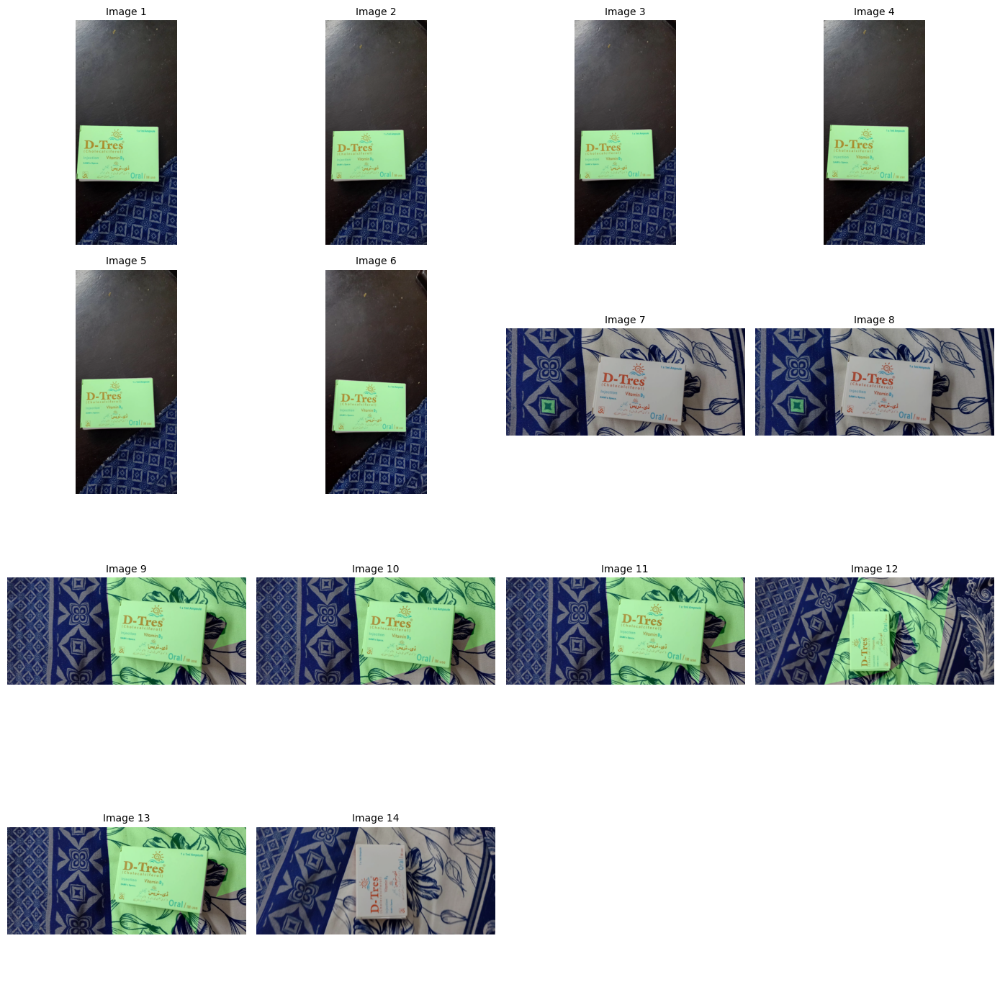

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def generate_medicine_mask(image):

    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    lower_white = np.array([0, 0, 125])
    upper_white = np.array([179, 90, 255])

    white_mask = cv2.inRange(
        hsv,
        lower_white,
        upper_white
    )

    kernel = np.ones((7, 7), np.uint8)

    cleaned = cv2.morphologyEx(
        white_mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    cleaned = cv2.morphologyEx(
        cleaned,
        cv2.MORPH_OPEN,
        kernel
    )

    contours, _ = cv2.findContours(
        cleaned,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    image_area = image.shape[0] * image.shape[1]

    candidates = []

    for contour in contours:

        area = cv2.contourArea(contour)

        if not (0.005 * image_area < area < 0.5 * image_area):
            continue

        x, y, w, h = cv2.boundingRect(contour)

        aspect_ratio = max(w, h) / max(min(w, h), 1)

        if aspect_ratio > 3.5:
            continue

        rectangularity = area / max(w * h, 1)

        if rectangularity < 0.60:
            continue

        candidates.append((area, contour))

    mask = np.zeros(image.shape[:2], dtype=np.uint8)

    if not candidates:
        return mask, False

    _, best_contour = max(
        candidates,
        key=lambda item: item[0]
    )

    perimeter = cv2.arcLength(best_contour, True)

    polygon = cv2.approxPolyDP(
        best_contour,
        0.02 * perimeter,
        True
    )

    cv2.drawContours(
        mask,
        [polygon],
        -1,
        255,
        cv2.FILLED
    )

    return mask, True


# Generate proposed masks
generated_masks = {}
failed_masks = []

for image_path in medicine_images:

    image = cv2.imread(str(image_path))

    if image is None:
        failed_masks.append(image_path.name)
        continue

    mask, found = generate_medicine_mask(image)

    generated_masks[image_path.name] = mask

    if not found:
        failed_masks.append(image_path.name)

print("=" * 45)
print("AUTOMATIC MASK GENERATION")
print("=" * 45)

print("Total images:", len(medicine_images))
print("Masks generated:", len(generated_masks))
print("Detection failures:", len(failed_masks))

if failed_masks:
    print("\nImages requiring correction:")
    for name in failed_masks:
        print("-", name)

# Preview the first 14 overlays
preview_images = medicine_images[:14]

fig, axes = plt.subplots(
    4, 4,
    figsize=(14, 14)
)

axes = axes.flatten()

for i, image_path in enumerate(preview_images):

    image = cv2.imread(str(image_path))
    mask = generated_masks[image_path.name]

    overlay = image.copy()

    green = np.zeros_like(image)
    green[:, :, 1] = mask

    overlay = cv2.addWeighted(
        image,
        0.75,
        green,
        0.25,
        0
    )

    axes[i].imshow(
        cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)
    )

    axes[i].set_title(
        f"Image {i + 1}",
        fontsize=10
    )

    axes[i].axis("off")

for i in range(len(preview_images), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Testing image: WhatsApp Image 2026-11-04 at 23.38.18 (1).jpeg
Resolution: (720, 1600)


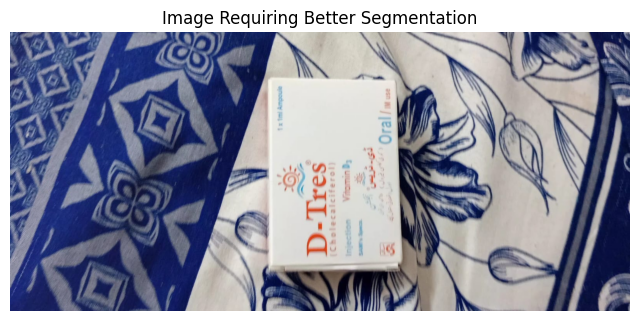

In [15]:
import cv2
import matplotlib.pyplot as plt

# Select the first image where detection failed
failed_name = failed_masks[0]

failed_path = next(
    path for path in medicine_images
    if path.name == failed_name
)

image = cv2.imread(str(failed_path))

print("Testing image:", failed_name)
print("Resolution:", image.shape[:2])

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Image Requiring Better Segmentation")
plt.axis("off")
plt.show()

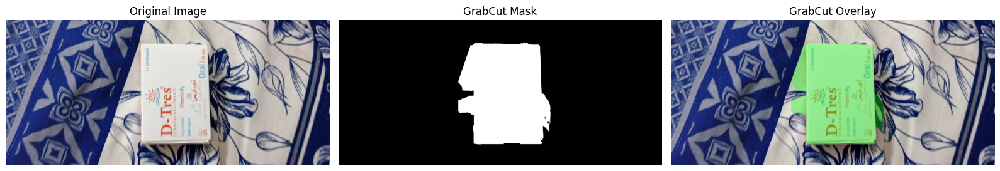

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the difficult image from Cell 15
img = image.copy()

h, w = img.shape[:2]

# Approximate rectangle around the medicine box
# Coordinates are based on this particular test image
x = int(w * 0.37)
y = int(h * 0.12)
rect_w = int(w * 0.30)
rect_h = int(h * 0.76)

rectangle = (x, y, rect_w, rect_h)

# Initialize GrabCut
grabcut_mask = np.zeros((h, w), np.uint8)

bg_model = np.zeros((1, 65), np.float64)
fg_model = np.zeros((1, 65), np.float64)

cv2.grabCut(
    img,
    grabcut_mask,
    rectangle,
    bg_model,
    fg_model,
    7,
    cv2.GC_INIT_WITH_RECT
)

# Convert GrabCut classes into binary mask
binary_mask = np.where(
    (grabcut_mask == cv2.GC_FGD) |
    (grabcut_mask == cv2.GC_PR_FGD),
    255,
    0
).astype(np.uint8)

# Keep largest foreground component
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8
    )
)

if num_labels > 1:

    largest_label = 1 + np.argmax(
        stats[1:, cv2.CC_STAT_AREA]
    )

    binary_mask = np.where(
        labels == largest_label,
        255,
        0
    ).astype(np.uint8)

# Generate overlay
overlay = img.copy()

overlay[binary_mask > 0] = (
    0.65 * overlay[binary_mask > 0] +
    0.35 * np.array([0, 255, 0])
).astype(np.uint8)

# Display
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(binary_mask, cmap="gray")
axes[1].set_title("GrabCut Mask")

axes[2].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
axes[2].set_title("GrabCut Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

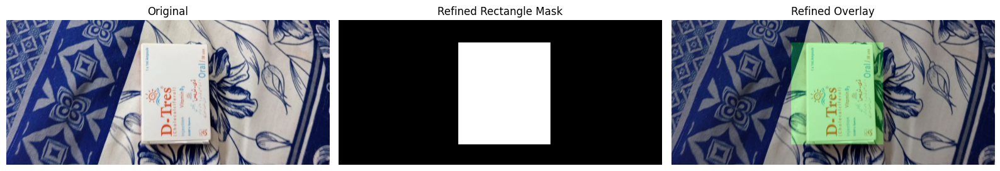

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Find the largest contour in the GrabCut mask
contours, _ = cv2.findContours(
    binary_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

if not contours:
    raise ValueError("No foreground contour found")

largest_contour = max(
    contours,
    key=cv2.contourArea
)

# Fit a rotated rectangle
rect = cv2.minAreaRect(largest_contour)

# Get four corners
box = cv2.boxPoints(rect)
box = np.round(box).astype(np.int32)

# Create rectangular segmentation mask
refined_mask = np.zeros(
    image.shape[:2],
    dtype=np.uint8
)

cv2.fillPoly(
    refined_mask,
    [box],
    255
)

# Create overlay
refined_overlay = image.copy()

green = np.zeros_like(image)
green[:, :, 1] = refined_mask

refined_overlay = cv2.addWeighted(
    image,
    0.75,
    green,
    0.25,
    0
)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(
    cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
)
axes[0].set_title("Original")

axes[1].imshow(refined_mask, cmap="gray")
axes[1].set_title("Refined Rectangle Mask")

axes[2].imshow(
    cv2.cvtColor(refined_overlay, cv2.COLOR_BGR2RGB)
)
axes[2].set_title("Refined Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Potential medicine-box centre:
X: 795
Y: 457
Detected coloured pixels: 4273


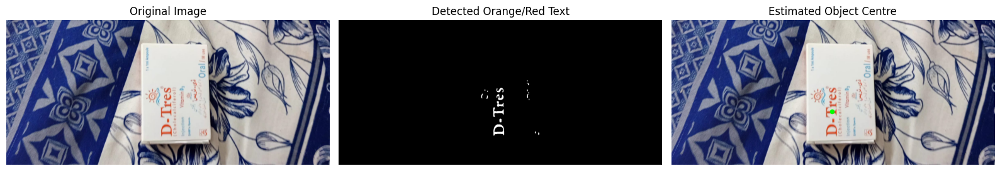

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the difficult image from our previous test
img = image.copy()

# Convert BGR to HSV
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Detect orange and red regions
orange_mask = cv2.inRange(
    hsv,
    np.array([0, 90, 70]),
    np.array([25, 255, 255])
)

red_mask = cv2.inRange(
    hsv,
    np.array([170, 90, 70]),
    np.array([179, 255, 255])
)

text_mask = cv2.bitwise_or(
    orange_mask,
    red_mask
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)

text_mask = cv2.morphologyEx(
    text_mask,
    cv2.MORPH_OPEN,
    kernel
)

# Find the detected coloured pixels
ys, xs = np.where(text_mask > 0)

preview = img.copy()

if len(xs) > 20:

    # Find approximate centre of orange/red text
    center_x = int(np.median(xs))
    center_y = int(np.median(ys))

    cv2.circle(
        preview,
        (center_x, center_y),
        12,
        (0, 255, 0),
        -1
    )

    print("Potential medicine-box centre:")
    print("X:", center_x)
    print("Y:", center_y)
    print("Detected coloured pixels:", len(xs))

else:
    print("Not enough orange/red pixels detected.")

# Display results
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(
    cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
)
axes[0].set_title("Original Image")

axes[1].imshow(
    text_mask,
    cmap="gray"
)
axes[1].set_title("Detected Orange/Red Text")

axes[2].imshow(
    cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)
)
axes[2].set_title("Estimated Object Centre")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

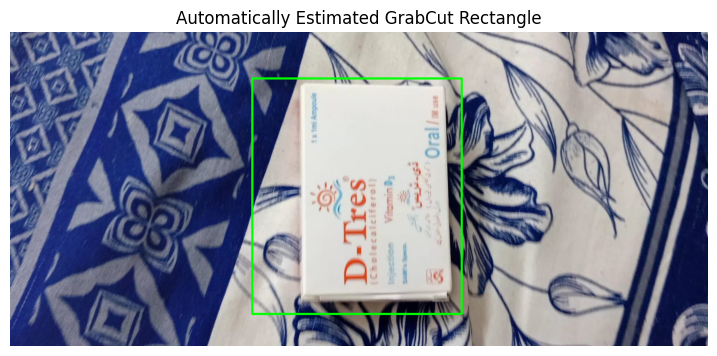

Rectangle: (555, 106, 480, 540)


In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the image and detected centre from Cell 18
test_image = image.copy()

h, w = test_image.shape[:2]

# Estimate a generous rectangle around the text centre
rect_width = int(w * 0.30)
rect_height = int(h * 0.75)

x = int(center_x - rect_width / 2)
y = int(center_y - rect_height * 0.65)

# Keep rectangle inside image
x = max(0, min(x, w - rect_width))
y = max(0, min(y, h - rect_height))

rectangle = (
    x,
    y,
    rect_width,
    rect_height
)

# Show initial rectangle
rectangle_preview = test_image.copy()

cv2.rectangle(
    rectangle_preview,
    (x, y),
    (x + rect_width, y + rect_height),
    (0, 255, 0),
    4
)

plt.figure(figsize=(9, 5))

plt.imshow(
    cv2.cvtColor(
        rectangle_preview,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Automatically Estimated GrabCut Rectangle")
plt.axis("off")
plt.show()

print("Rectangle:", rectangle)

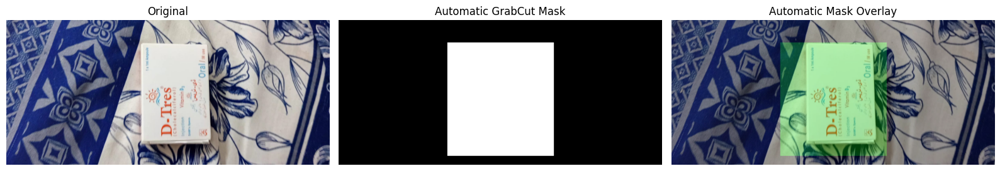

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = image.copy()
h, w = img.shape[:2]

# Add a small margin around the detected rectangle
margin = 30

x1 = max(1, x - margin)
y1 = max(1, y - margin)

x2 = min(w - 1, x + rect_width + margin)
y2 = min(h - 1, y + rect_height + margin)

auto_rect = (
    x1,
    y1,
    x2 - x1,
    y2 - y1
)

# Initialize GrabCut
gc_mask = np.zeros((h, w), np.uint8)

bg_model = np.zeros((1, 65), np.float64)
fg_model = np.zeros((1, 65), np.float64)

cv2.grabCut(
    img,
    gc_mask,
    auto_rect,
    bg_model,
    fg_model,
    5,
    cv2.GC_INIT_WITH_RECT
)

# Convert GrabCut output to binary mask
auto_mask = np.where(
    (gc_mask == cv2.GC_FGD) |
    (gc_mask == cv2.GC_PR_FGD),
    255,
    0
).astype(np.uint8)

# Find contours
contours, _ = cv2.findContours(
    auto_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

if contours:

    largest = max(contours, key=cv2.contourArea)

    # Fit a rotated rectangle
    fitted_rect = cv2.minAreaRect(largest)

    corners = cv2.boxPoints(fitted_rect)
    corners = np.round(corners).astype(np.int32)

    final_mask = np.zeros((h, w), dtype=np.uint8)

    cv2.fillPoly(
        final_mask,
        [corners],
        255
    )

else:
    final_mask = np.zeros((h, w), dtype=np.uint8)

# Create overlay
overlay = img.copy()

green = np.zeros_like(img)
green[:, :, 1] = final_mask

overlay = cv2.addWeighted(
    img,
    0.75,
    green,
    0.25,
    0
)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original")

axes[1].imshow(final_mask, cmap="gray")
axes[1].set_title("Automatic GrabCut Mask")

axes[2].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
axes[2].set_title("Automatic Mask Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
from google.colab import files

uploaded = files.upload()

Saving medicine_box_annotations_corrected.zip to medicine_box_annotations_corrected.zip


In [22]:
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path
from PIL import Image, ImageDraw
import numpy as np

# Input annotation ZIP
ANNOTATION_ZIP = Path(
    "/content/medicine_box_annotations_corrected.zip"
)

# Output directory
MASK_DIR = Path("/content/medicine_box_masks")
MASK_DIR.mkdir(parents=True, exist_ok=True)

# Read XML from ZIP
with zipfile.ZipFile(ANNOTATION_ZIP, "r") as z:
    xml_data = z.read("annotations.xml")

root = ET.fromstring(xml_data)

generated = 0
empty_masks = []
invalid_images = []

for image_element in root.findall("image"):

    filename = image_element.attrib["name"]

    width = int(image_element.attrib["width"])
    height = int(image_element.attrib["height"])

    # Create black mask
    mask = Image.new(
        "L",
        (width, height),
        color=0
    )

    draw = ImageDraw.Draw(mask)

    polygons = image_element.findall("polygon")

    if len(polygons) != 1:
        invalid_images.append(filename)
        continue

    polygon = polygons[0]

    if polygon.attrib.get("label") != "medicine_box":
        invalid_images.append(filename)
        continue

    # Convert CVAT polygon coordinates
    points = []

    for point in polygon.attrib["points"].split(";"):

        x, y = map(float, point.split(","))

        points.append((x, y))

    # Draw white medicine-box region
    draw.polygon(
        points,
        fill=255
    )

    # Save mask with matching filename stem
    output_name = Path(filename).stem + ".png"

    output_path = MASK_DIR / output_name

    mask.save(output_path)

    # Check mask is not empty
    mask_array = np.array(mask)

    if np.count_nonzero(mask_array) == 0:
        empty_masks.append(filename)

    generated += 1

print("=" * 50)
print("SEGMENTATION MASK GENERATION")
print("=" * 50)

print("Masks generated:", generated)
print("Empty masks:", len(empty_masks))
print("Invalid annotations:", len(invalid_images))

print("\nMask directory:", MASK_DIR)

# Verify count and pixel values
mask_files = sorted(MASK_DIR.glob("*.png"))

assert len(mask_files) == 70, (
    f"Expected 70 masks, found {len(mask_files)}"
)

assert len(empty_masks) == 0
assert len(invalid_images) == 0

for mask_path in mask_files:

    mask_array = np.array(
        Image.open(mask_path)
    )

    values = set(np.unique(mask_array))

    assert values.issubset({0, 255}), (
        f"Invalid mask values: {mask_path.name}"
    )

print("\nPASS: All 70 binary masks generated successfully!")

SEGMENTATION MASK GENERATION
Masks generated: 70
Empty masks: 0
Invalid annotations: 0

Mask directory: /content/medicine_box_masks

PASS: All 70 binary masks generated successfully!


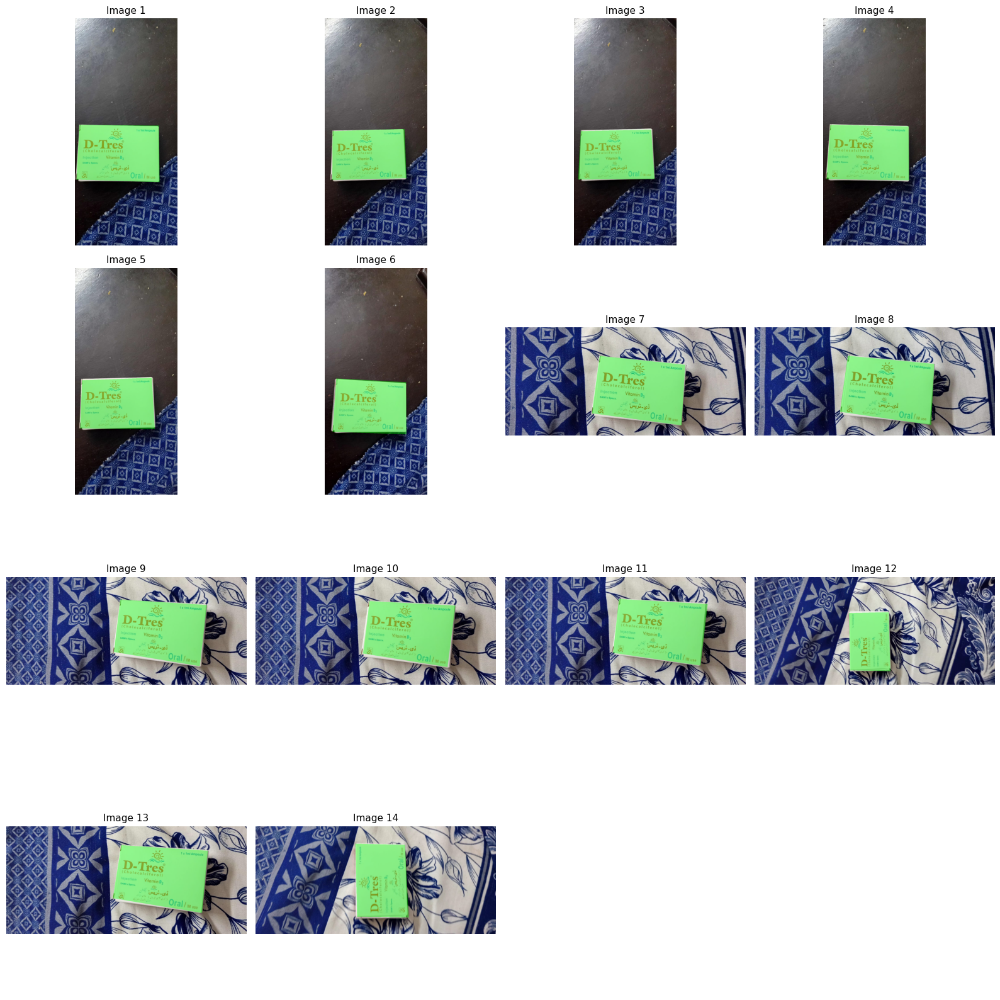

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Preview first 14 image-mask pairs
preview_paths = medicine_images[:14]

fig, axes = plt.subplots(
    4, 4,
    figsize=(16, 16)
)

axes = axes.flatten()

for i, image_path in enumerate(preview_paths):

    # Load original photograph
    image = cv2.imread(str(image_path))

    # Find matching mask
    mask_path = MASK_DIR / (
        image_path.stem + ".png"
    )

    mask = np.array(
        Image.open(mask_path).convert("L")
    )

    # Confirm dimensions match
    assert mask.shape == image.shape[:2], (
        f"Dimension mismatch: {image_path.name}"
    )

    # Create green overlay
    overlay = image.copy()

    overlay[mask > 0] = (
        0.6 * overlay[mask > 0] +
        0.4 * np.array([0, 255, 0])
    ).astype(np.uint8)

    axes[i].imshow(
        cv2.cvtColor(
            overlay,
            cv2.COLOR_BGR2RGB
        )
    )

    axes[i].set_title(
        f"Image {i + 1}",
        fontsize=11
    )

    axes[i].axis("off")

# Hide unused plots
for j in range(len(preview_paths), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

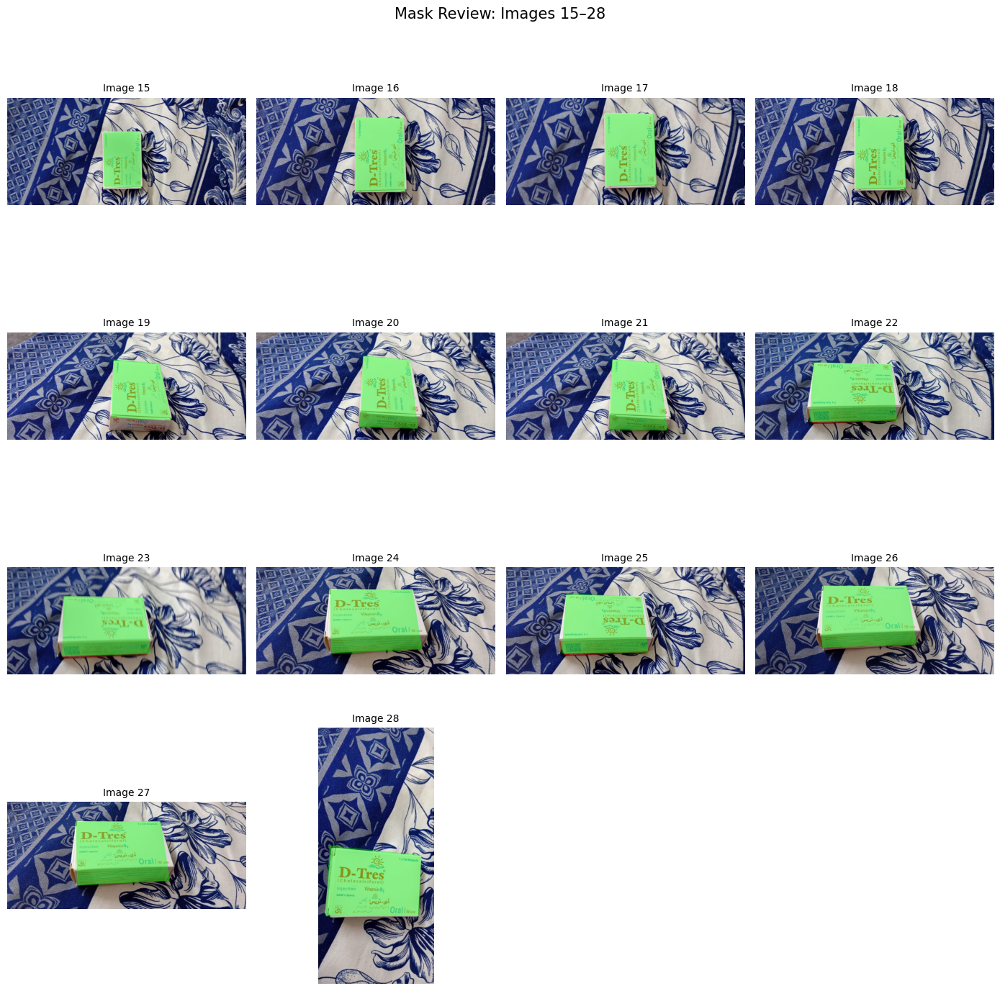

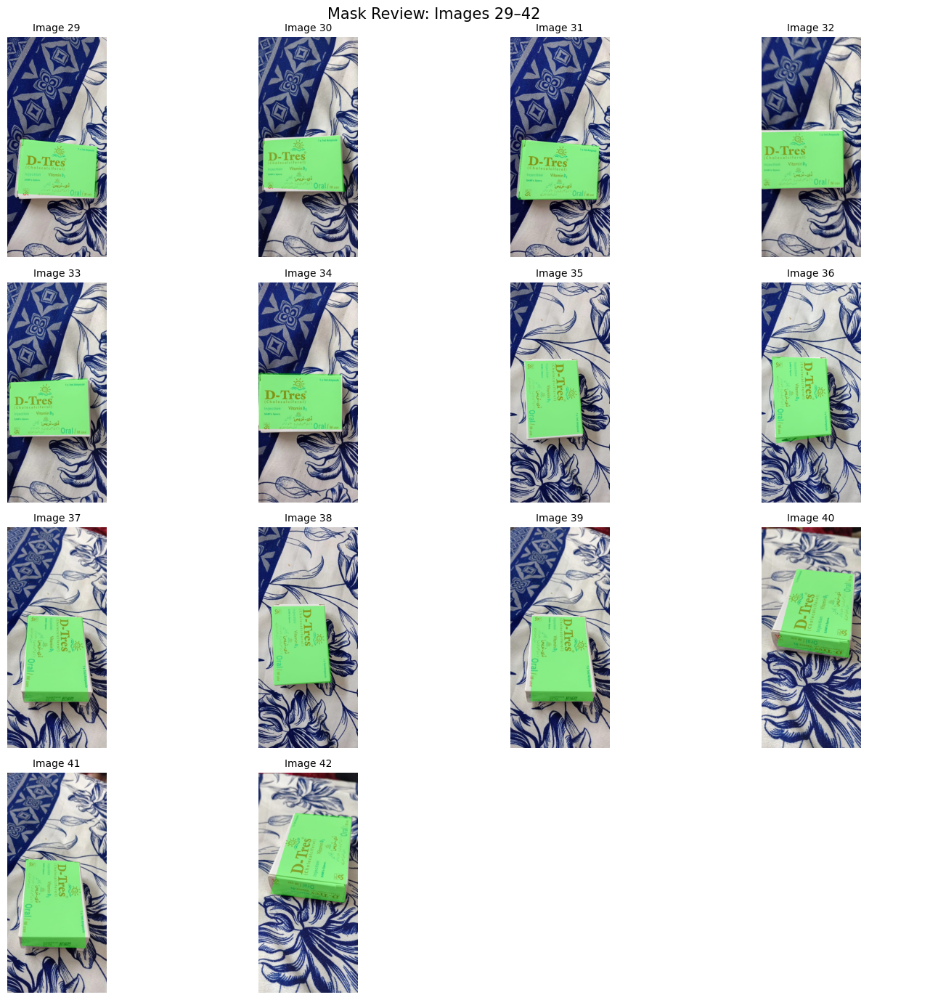

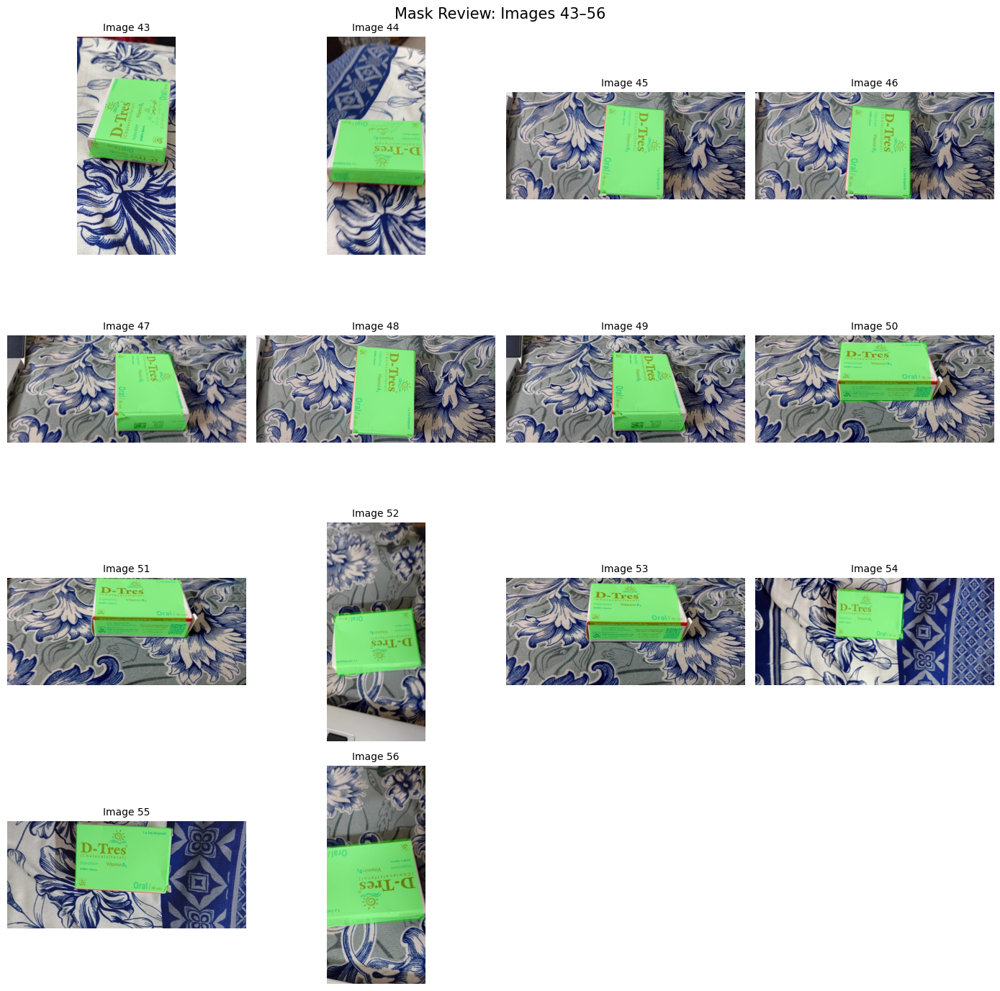

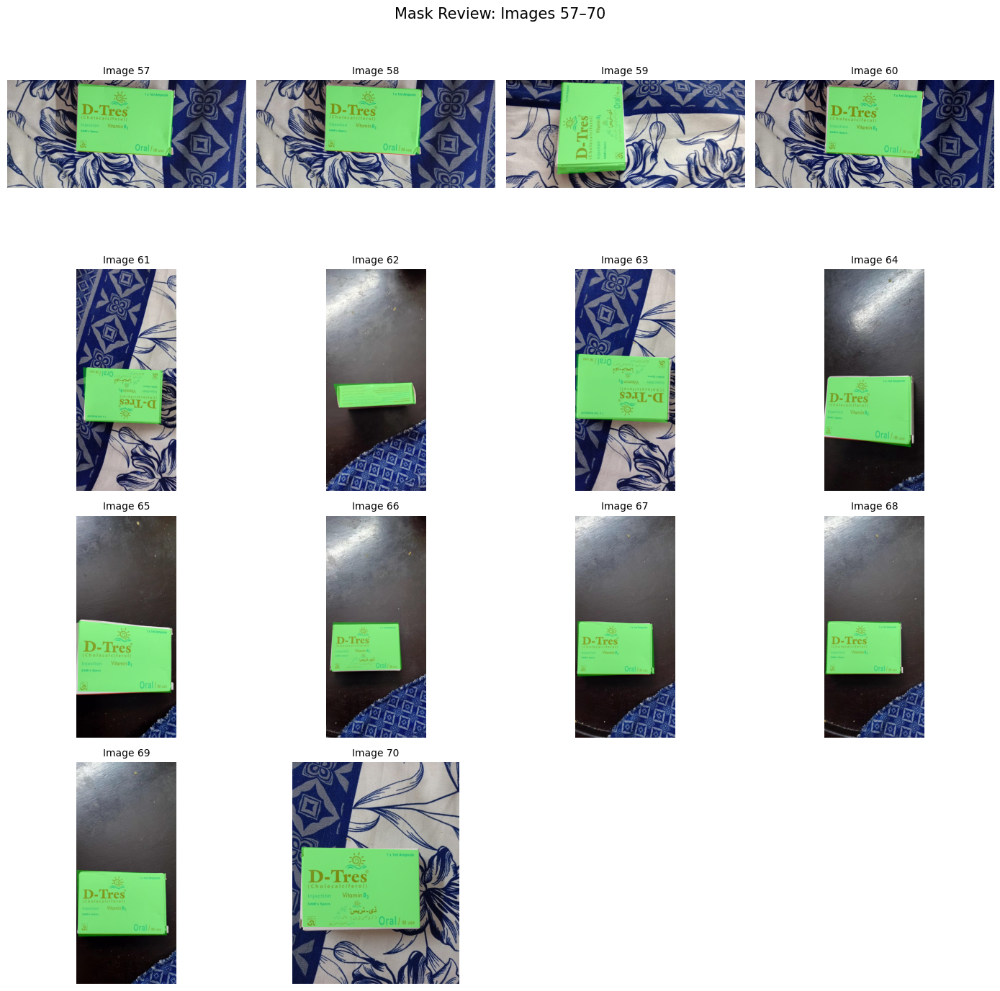

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Display remaining images in batches of 14
for start in range(14, len(medicine_images), 14):

    batch = medicine_images[start:start + 14]

    fig, axes = plt.subplots(
        4, 4,
        figsize=(14, 14)
    )

    axes = axes.flatten()

    for i, image_path in enumerate(batch):

        image = cv2.imread(str(image_path))

        mask_path = MASK_DIR / (
            image_path.stem + ".png"
        )

        mask = np.array(
            Image.open(mask_path).convert("L")
        )

        assert mask.shape == image.shape[:2]

        overlay = image.copy()

        overlay[mask > 0] = (
            0.6 * overlay[mask > 0] +
            0.4 * np.array([0, 255, 0])
        ).astype(np.uint8)

        axes[i].imshow(
            cv2.cvtColor(
                overlay,
                cv2.COLOR_BGR2RGB
            )
        )

        axes[i].set_title(
            f"Image {start + i + 1}",
            fontsize=10
        )

        axes[i].axis("off")

    for j in range(len(batch), len(axes)):
        axes[j].axis("off")

    plt.suptitle(
        f"Mask Review: Images {start + 1}"
        f"–{start + len(batch)}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

In [25]:
from pathlib import Path
import shutil

# Google Drive project directory
BASE = Path("/content/drive/MyDrive/MeasureIt")

IMAGE_DEST = BASE / "dataset" / "images"
MASK_DEST = BASE / "dataset" / "masks"
SPLIT_DEST = BASE / "dataset" / "splits"

# Create directories
for folder in [IMAGE_DEST, MASK_DEST, SPLIT_DEST]:
    folder.mkdir(parents=True, exist_ok=True)

# Save original photographs
for image_path in medicine_images:
    shutil.copy2(
        image_path,
        IMAGE_DEST / image_path.name
    )

# Save segmentation masks
for mask_path in MASK_DIR.glob("*.png"):
    shutil.copy2(
        mask_path,
        MASK_DEST / mask_path.name
    )

# Save fixed split files
for filename in ["train.txt", "val.txt", "test.txt"]:

    source = Path(
        "/content/medicine_box_splits"
    ) / filename

    shutil.copy2(
        source,
        SPLIT_DEST / filename
    )

print("=" * 45)
print("DATASET SAVED TO GOOGLE DRIVE")
print("=" * 45)

print("Images:", len(list(IMAGE_DEST.iterdir())))
print("Masks:", len(list(MASK_DEST.glob("*.png"))))
print("Split files:", len(list(SPLIT_DEST.glob("*.txt"))))

print("\nLocation:", BASE / "dataset")

# Verify expected counts
assert len(list(IMAGE_DEST.iterdir())) == 70
assert len(list(MASK_DEST.glob("*.png"))) == 70
assert len(list(SPLIT_DEST.glob("*.txt"))) == 3

print("\nPASS: Dataset backup completed!")

DATASET SAVED TO GOOGLE DRIVE
Images: 70
Masks: 70
Split files: 3

Location: /content/drive/MyDrive/MeasureIt/dataset

PASS: Dataset backup completed!


In [26]:
import torch
import cv2
import numpy as np
import platform
import os
import sys

print("=" * 45)
print("TRAINING ENVIRONMENT")
print("=" * 45)

print("Python:", sys.version.split()[0])
print("Operating system:", platform.platform())
print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("CPU threads:", os.cpu_count())

device = torch.device("cpu")

print("\nSelected device:", device)
print("CUDA available:", torch.cuda.is_available())

# Use a fixed random seed
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

print("Random seed:", SEED)

# Verify Google Drive files
from pathlib import Path

BASE = Path("/content/drive/MyDrive/MeasureIt")

IMAGE_DIR = BASE / "dataset" / "images"
MASK_DIR = BASE / "dataset" / "masks"
SPLIT_DIR = BASE / "dataset" / "splits"

print("\nDataset verification:")
print("Images:", len(list(IMAGE_DIR.iterdir())))
print("Masks:", len(list(MASK_DIR.glob("*.png"))))
print("Splits:", len(list(SPLIT_DIR.glob("*.txt"))))

assert len(list(IMAGE_DIR.iterdir())) == 70
assert len(list(MASK_DIR.glob("*.png"))) == 70

print("\nPASS: Training environment ready!")

TRAINING ENVIRONMENT
Python: 3.13.18
Operating system: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cpu
OpenCV: 4.14.0
NumPy: 2.4.6
CPU threads: 2

Selected device: cpu
CUDA available: False
Random seed: 42

Dataset verification:
Images: 70
Masks: 70
Splits: 3

PASS: Training environment ready!


In [27]:
import cv2
import numpy as np
from pathlib import Path

BASE = Path("/content/drive/MyDrive/MeasureIt")

IMAGE_DIR = BASE / "dataset" / "images"
MASK_DIR = BASE / "dataset" / "masks"

PROCESSED_IMAGES = BASE / "dataset" / "processed_images"
PROCESSED_MASKS = BASE / "dataset" / "processed_masks"

PROCESSED_IMAGES.mkdir(parents=True, exist_ok=True)
PROCESSED_MASKS.mkdir(parents=True, exist_ok=True)

# Load calibration
calibration = np.load(
    BASE / "calibration" / "camera_calibration.npz"
)

camera_matrix = calibration["camera_matrix"]
dist_coeffs = calibration["dist_coeffs"]

TARGET_SIZE = (256, 256)
CALIBRATED_SIZE = (1600, 720)

processed_count = 0
undistorted_count = 0
uncalibrated_files = []

for image_path in sorted(IMAGE_DIR.iterdir()):

    if image_path.suffix.lower() not in [
        ".jpg", ".jpeg", ".png"
    ]:
        continue

    mask_path = MASK_DIR / (
        image_path.stem + ".png"
    )

    image = cv2.imread(str(image_path))

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None or mask is None:
        raise ValueError(
            f"Missing image or mask: {image_path.name}"
        )

    if image.shape[:2] != mask.shape:
        raise ValueError(
            f"Image-mask mismatch: {image_path.name}"
        )

    h, w = image.shape[:2]

    # Rotate portrait 720 × 1600 images
    # to the calibrated 1600 × 720 orientation
    if (w, h) == (720, 1600):

        image = cv2.rotate(
            image,
            cv2.ROTATE_90_CLOCKWISE
        )

        mask = cv2.rotate(
            mask,
            cv2.ROTATE_90_CLOCKWISE
        )

    current_h, current_w = image.shape[:2]

    # Apply undistortion only at matching resolution
    if (current_w, current_h) == CALIBRATED_SIZE:

        map_x, map_y = cv2.initUndistortRectifyMap(
            camera_matrix,
            dist_coeffs,
            None,
            camera_matrix,
            CALIBRATED_SIZE,
            cv2.CV_32FC1
        )

        image = cv2.remap(
            image,
            map_x,
            map_y,
            cv2.INTER_LINEAR
        )

        mask = cv2.remap(
            mask,
            map_x,
            map_y,
            cv2.INTER_NEAREST
        )

        undistorted_count += 1

    else:
        uncalibrated_files.append(image_path.name)

    # Resize image
    image = cv2.resize(
        image,
        TARGET_SIZE,
        interpolation=cv2.INTER_AREA
    )

    # Resize mask using nearest-neighbour interpolation
    mask = cv2.resize(
        mask,
        TARGET_SIZE,
        interpolation=cv2.INTER_NEAREST
    )

    # Ensure binary mask
    mask = np.where(
        mask >= 128,
        255,
        0
    ).astype(np.uint8)

    # Save with matching stems
    cv2.imwrite(
        str(PROCESSED_IMAGES / image_path.name),
        image
    )

    cv2.imwrite(
        str(PROCESSED_MASKS / mask_path.name),
        mask
    )

    processed_count += 1

print("=" * 50)
print("PREPROCESSING RESULTS")
print("=" * 50)

print("Images processed:", processed_count)
print("Images undistorted:", undistorted_count)
print("Images without compatible calibration:",
      len(uncalibrated_files))

print("\nUncalibrated files:")
for filename in uncalibrated_files:
    print("-", filename)

assert processed_count == 70

print("\nPASS: Image-mask preprocessing completed!")

PREPROCESSING RESULTS
Images processed: 70
Images undistorted: 69
Images without compatible calibration: 1

Uncalibrated files:
- WhatsApp Image 2026-11-04 at 23.38.47.jpeg

PASS: Image-mask preprocessing completed!


In [28]:
import torch
import cv2
import numpy as np

from torch.utils.data import Dataset, DataLoader
from pathlib import Path

# Fixed random seed
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

BASE = Path("/content/drive/MyDrive/MeasureIt")

PROCESSED_IMAGES = BASE / "dataset" / "processed_images"
PROCESSED_MASKS = BASE / "dataset" / "processed_masks"
SPLIT_DIR = BASE / "dataset" / "splits"

# Read committed split filenames
def load_split(filename):

    path = SPLIT_DIR / filename

    with open(path, "r", encoding="utf-8") as f:
        return [
            line.strip()
            for line in f
            if line.strip()
        ]


train_files = load_split("train.txt")
val_files = load_split("val.txt")
test_files = load_split("test.txt")

# Check fixed split
assert len(train_files) == 49
assert len(val_files) == 14
assert len(test_files) == 7

assert not set(train_files) & set(val_files)
assert not set(train_files) & set(test_files)
assert not set(val_files) & set(test_files)


class MedicineBoxDataset(Dataset):

    def __init__(self, filenames):
        self.filenames = filenames

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):

        filename = self.filenames[idx]

        image_path = PROCESSED_IMAGES / filename

        mask_path = PROCESSED_MASKS / (
            Path(filename).stem + ".png"
        )

        image = cv2.imread(str(image_path))

        if image is None:
            raise FileNotFoundError(image_path)

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        mask = cv2.imread(
            str(mask_path),
            cv2.IMREAD_GRAYSCALE
        )

        if mask is None:
            raise FileNotFoundError(mask_path)

        # Convert pixels to [0, 1]
        image = image.astype(np.float32) / 255.0

        # ImageNet normalization for pretrained encoder
        mean = np.array(
            [0.485, 0.456, 0.406],
            dtype=np.float32
        )

        std = np.array(
            [0.229, 0.224, 0.225],
            dtype=np.float32
        )

        image = (image - mean) / std

        # Binary segmentation mask
        mask = (
            mask.astype(np.float32) / 255.0
        )

        # Convert image from HWC to CHW
        image = np.transpose(
            image,
            (2, 0, 1)
        )

        # Add mask channel
        mask = np.expand_dims(mask, axis=0)

        return (
            torch.from_numpy(image.copy()),
            torch.from_numpy(mask.copy())
        )


# Create datasets
train_dataset = MedicineBoxDataset(train_files)
val_dataset = MedicineBoxDataset(val_files)
test_dataset = MedicineBoxDataset(test_files)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("=" * 45)
print("PYTORCH DATASET SUMMARY")
print("=" * 45)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

# Verify a sample batch
images_batch, masks_batch = next(
    iter(train_loader)
)

print("\nImage batch shape:", images_batch.shape)
print("Mask batch shape:", masks_batch.shape)

print("\nPASS: DataLoaders created successfully!")

PYTORCH DATASET SUMMARY
Training: 49
Validation: 14
Testing: 7

Image batch shape: torch.Size([4, 3, 256, 256])
Mask batch shape: torch.Size([4, 1, 256, 256])

PASS: DataLoaders created successfully!


In [29]:
%pip install -q segmentation-models-pytorch

In [30]:
import torch
import segmentation_models_pytorch as smp

device = torch.device("cpu")

# Create U-Net with pretrained MobileNetV2 encoder
model = smp.Unet(
    encoder_name="mobilenet_v2",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
)

model = model.to(device)

# Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=" * 45)
print("U-NET MODEL SUMMARY")
print("=" * 45)

print("Architecture: U-Net")
print("Encoder: MobileNetV2")
print("Pretrained weights: ImageNet")
print("Input channels: 3")
print("Output channels: 1")
print("Device:", device)

print("\nTotal parameters:", total_params)
print("Trainable parameters:", trainable_params)

# Test one forward pass
model.eval()

with torch.no_grad():

    sample_images, _ = next(iter(train_loader))

    sample_images = sample_images.to(device)

    output = model(sample_images)

print("\nModel output shape:", output.shape)

assert output.shape == (4, 1, 256, 256)

print("\nPASS: U-Net initialized successfully!")

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

U-NET MODEL SUMMARY
Architecture: U-Net
Encoder: MobileNetV2
Pretrained weights: ImageNet
Input channels: 3
Output channels: 1
Device: cpu

Total parameters: 6628945
Trainable parameters: 6628945

Model output shape: torch.Size([4, 1, 256, 256])

PASS: U-Net initialized successfully!


In [31]:
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
import numpy as np
import time
from pathlib import Path

# CPU configuration
device = torch.device("cpu")
torch.set_num_threads(2)

# Freeze pretrained encoder for faster CPU training
for param in model.encoder.parameters():
    param.requires_grad = False

# Loss functions
bce_loss = nn.BCEWithLogitsLoss()

dice_loss = smp.losses.DiceLoss(
    mode="binary",
    from_logits=True
)

def combined_loss(predictions, targets):
    return (
        0.5 * bce_loss(predictions, targets) +
        0.5 * dice_loss(predictions, targets)
    )

# Optimizer for trainable parameters only
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

def calculate_iou(logits, masks):

    predictions = (
        torch.sigmoid(logits) > 0.5
    ).float()

    intersection = (
        predictions * masks
    ).sum(dim=(1, 2, 3))

    union = (
        predictions + masks -
        predictions * masks
    ).sum(dim=(1, 2, 3))

    iou = (intersection + 1e-6) / (
        union + 1e-6
    )

    return iou.mean().item()


# Training settings
EPOCHS = 8
PATIENCE = 3

best_val_iou = -1.0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_iou": [],
    "val_iou": []
}

MODEL_DIR = Path(
    "/content/drive/MyDrive/MeasureIt/models"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "best_unet_mobilenetv2.pth"

print("=" * 55)
print("STARTING U-NET TRAINING")
print("=" * 55)

start_time = time.time()

for epoch in range(EPOCHS):

    # ----------------------------
    # TRAINING
    # ----------------------------
    model.train()

    # Keep frozen encoder BatchNorm statistics fixed
    model.encoder.eval()

    train_loss_total = 0.0
    train_iou_total = 0.0
    train_samples = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        train_loss_total += loss.item() * batch_size

        train_iou_total += (
            calculate_iou(outputs.detach(), masks)
            * batch_size
        )

        train_samples += batch_size

    avg_train_loss = train_loss_total / train_samples
    avg_train_iou = train_iou_total / train_samples

    # ----------------------------
    # VALIDATION
    # ----------------------------
    model.eval()

    val_loss_total = 0.0
    val_iou_total = 0.0
    val_samples = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = combined_loss(outputs, masks)

            batch_size = images.size(0)

            val_loss_total += loss.item() * batch_size

            val_iou_total += (
                calculate_iou(outputs, masks)
                * batch_size
            )

            val_samples += batch_size

    avg_val_loss = val_loss_total / val_samples
    avg_val_iou = val_iou_total / val_samples

    # Save history
    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["train_iou"].append(avg_train_iou)
    history["val_iou"].append(avg_val_iou)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Train IoU: {avg_train_iou:.4f} | "
        f"Val IoU: {avg_val_iou:.4f}",
        flush=True
    )

    # Save best model using validation IoU only
    if avg_val_iou > best_val_iou + 1e-5:

        best_val_iou = avg_val_iou
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": epoch + 1,
                "best_val_iou": best_val_iou,
                "architecture": "Unet",
                "encoder": "mobilenet_v2",
                "input_size": 256,
                "seed": 42
            },
            MODEL_PATH
        )

        print("  Best model saved!")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break


training_seconds = time.time() - start_time

print("\n" + "=" * 55)
print("TRAINING COMPLETE")
print("=" * 55)

print("Best validation IoU:", round(best_val_iou, 4))
print("Training time (minutes):",
      round(training_seconds / 60, 2))
print("Model saved at:", MODEL_PATH)

STARTING U-NET TRAINING
Epoch 1/8 | Train Loss: 0.6022 | Val Loss: 0.5859 | Train IoU: 0.3270 | Val IoU: 0.4019
  Best model saved!
Epoch 2/8 | Train Loss: 0.4577 | Val Loss: 0.4139 | Train IoU: 0.5616 | Val IoU: 0.5930
  Best model saved!
Epoch 3/8 | Train Loss: 0.3845 | Val Loss: 0.4128 | Train IoU: 0.6964 | Val IoU: 0.6175
  Best model saved!
Epoch 4/8 | Train Loss: 0.3319 | Val Loss: 0.3444 | Train IoU: 0.7996 | Val IoU: 0.7332
  Best model saved!
Epoch 5/8 | Train Loss: 0.2926 | Val Loss: 0.3141 | Train IoU: 0.8567 | Val IoU: 0.7885
  Best model saved!
Epoch 6/8 | Train Loss: 0.2612 | Val Loss: 0.2767 | Train IoU: 0.8938 | Val IoU: 0.8016
  Best model saved!
Epoch 7/8 | Train Loss: 0.2338 | Val Loss: 0.2455 | Train IoU: 0.9191 | Val IoU: 0.8071
  Best model saved!
Epoch 8/8 | Train Loss: 0.2164 | Val Loss: 0.2356 | Train IoU: 0.9254 | Val IoU: 0.8158
  Best model saved!

TRAINING COMPLETE
Best validation IoU: 0.8158
Training time (minutes): 2.6
Model saved at: /content/drive/MyDri

In [32]:
# CELL 32 — FINAL U-NET TEST EVALUATION

import os
import json
import numpy as np
import torch

MODEL_PATH = "/content/drive/MyDrive/MeasureIt/models/best_unet_mobilenetv2.pth"
RESULTS_DIR = "/content/drive/MyDrive/MeasureIt/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

device = torch.device("cpu")

# Load the best validation checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("=" * 55)
print("FINAL TEST EVALUATION")
print("=" * 55)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Validation IoU:", checkpoint["best_val_iou"])
print("Test images:", len(test_loader.dataset))

all_predictions = []
all_ground_truths = []
all_scores = []
test_results = []

with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(test_loader):

        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).float()

        for i in range(images.size(0)):

            pred = predictions[i, 0].cpu().numpy().astype(bool)
            gt = (masks[i, 0].cpu().numpy() >= 0.5)

            probs = probabilities[i, 0].cpu().numpy()

            intersection = np.logical_and(pred, gt).sum()
            union = np.logical_or(pred, gt).sum()

            tp = intersection
            fp = np.logical_and(pred, ~gt).sum()
            fn = np.logical_and(~pred, gt).sum()

            iou = (
                intersection / union
                if union > 0 else 1.0
            )

            precision = (
                tp / (tp + fp)
                if (tp + fp) > 0 else 0.0
            )

            recall = (
                tp / (tp + fn)
                if (tp + fn) > 0 else 0.0
            )

            # Confidence proxy for this one-object prediction.
            # This is NOT a calibrated detection confidence.
            confidence = (
                float(probs[pred].mean())
                if pred.any() else 0.0
            )

            result = {
                "image_index": len(test_results) + 1,
                "iou": float(iou),
                "precision": float(precision),
                "recall": float(recall),
                "confidence_proxy": confidence
            }

            test_results.append(result)

            all_predictions.append(pred)
            all_ground_truths.append(gt)
            all_scores.append(confidence)

# Mean per-image segmentation metrics
mean_iou = np.mean([r["iou"] for r in test_results])
mean_precision = np.mean([r["precision"] for r in test_results])
mean_recall = np.mean([r["recall"] for r in test_results])


# --------------------------------------------------
# INSTANCE-LEVEL AP FOR THE SINGLE-OBJECT DATASET
# --------------------------------------------------
# Each image contains one medicine-box instance.
# We have at most one predicted instance per image.
# Predictions are ranked using the confidence proxy.
#
# This is NOT COCO mAP from a dedicated instance
# segmentation detector. Document this distinction.

def average_precision_at_iou(iou_threshold):

    order = np.argsort(-np.asarray(all_scores))

    total_gt = sum(gt.any() for gt in all_ground_truths)

    if total_gt == 0:
        return float("nan")

    tp_list = []
    fp_list = []

    for idx in order:

        pred = all_predictions[idx]
        gt = all_ground_truths[idx]

        if not pred.any():
            continue

        intersection = np.logical_and(pred, gt).sum()
        union = np.logical_or(pred, gt).sum()

        pred_iou = intersection / union if union > 0 else 0.0

        if gt.any() and pred_iou >= iou_threshold:
            tp_list.append(1)
            fp_list.append(0)
        else:
            tp_list.append(0)
            fp_list.append(1)

    if len(tp_list) == 0:
        return 0.0

    tp_cum = np.cumsum(tp_list)
    fp_cum = np.cumsum(fp_list)

    recall_curve = tp_cum / total_gt
    precision_curve = tp_cum / np.maximum(
        tp_cum + fp_cum, 1
    )

    # All-point interpolated AP
    mrec = np.concatenate(([0], recall_curve, [1]))
    mpre = np.concatenate(([0], precision_curve, [0]))

    for j in range(len(mpre) - 2, -1, -1):
        mpre[j] = max(mpre[j], mpre[j + 1])

    change = np.where(mrec[1:] != mrec[:-1])[0]

    ap = np.sum(
        (mrec[change + 1] - mrec[change])
        * mpre[change + 1]
    )

    return float(ap)


ap50 = average_precision_at_iou(0.50)

iou_thresholds = np.arange(0.50, 1.00, 0.05)

ap_values = [
    average_precision_at_iou(float(t))
    for t in iou_thresholds
]

map50_95 = float(np.mean(ap_values))


# --------------------------------------------------
# REPORT
# --------------------------------------------------

summary = {
    "test_images": len(test_results),
    "test_mean_iou": float(mean_iou),
    "test_mean_pixel_precision": float(mean_precision),
    "test_mean_pixel_recall": float(mean_recall),
    "single_class_instance_ap50": float(ap50),
    "single_class_instance_map50_95": float(map50_95),
    "metric_note": (
        "AP computed using one predicted medicine-box mask "
        "per image, with mean foreground probability as an "
        "uncalibrated confidence proxy. Not COCO detector mAP."
    )
}

print("\n" + "=" * 55)
print("FINAL TEST RESULTS")
print("=" * 55)

print(f"Test images:            {len(test_results)}")
print(f"Mean IoU:               {mean_iou:.4f}")
print(f"Pixel Precision:        {mean_precision:.4f}")
print(f"Pixel Recall:           {mean_recall:.4f}")
print(f"Single-class AP@0.50:   {ap50:.4f}")
print(f"Single-class mAP@0.5:0.95: {map50_95:.4f}")

print("\nPer-image results:")

for result in test_results:
    print(
        f"Image {result['image_index']}: "
        f"IoU={result['iou']:.4f}, "
        f"Precision={result['precision']:.4f}, "
        f"Recall={result['recall']:.4f}"
    )

# Save results
output_path = os.path.join(
    RESULTS_DIR,
    "test_metrics.json"
)

with open(output_path, "w") as f:
    json.dump(
        {
            "summary": summary,
            "per_image_results": test_results,
            "ap_by_iou_threshold": {
                f"{t:.2f}": float(ap)
                for t, ap in zip(iou_thresholds, ap_values)
            }
        },
        f,
        indent=4
    )

print("\nResults saved:", output_path)
print("\nPASS: Test evaluation completed!")

FINAL TEST EVALUATION
Checkpoint epoch: 8
Validation IoU: 0.8157810951982226
Test images: 7

FINAL TEST RESULTS
Test images:            7
Mean IoU:               0.8749
Pixel Precision:        0.9175
Pixel Recall:           0.9528
Single-class AP@0.50:   1.0000
Single-class mAP@0.5:0.95: 0.8119

Per-image results:
Image 1: IoU=0.8829, Precision=0.8874, Recall=0.9943
Image 2: IoU=0.8001, Precision=0.8590, Recall=0.9211
Image 3: IoU=0.9099, Precision=0.9233, Recall=0.9843
Image 4: IoU=0.9021, Precision=0.9132, Recall=0.9867
Image 5: IoU=0.7878, Precision=0.9875, Recall=0.7957
Image 6: IoU=0.9178, Precision=0.9222, Recall=0.9949
Image 7: IoU=0.9238, Precision=0.9299, Recall=0.9929

Results saved: /content/drive/MyDrive/MeasureIt/results/test_metrics.json

PASS: Test evaluation completed!


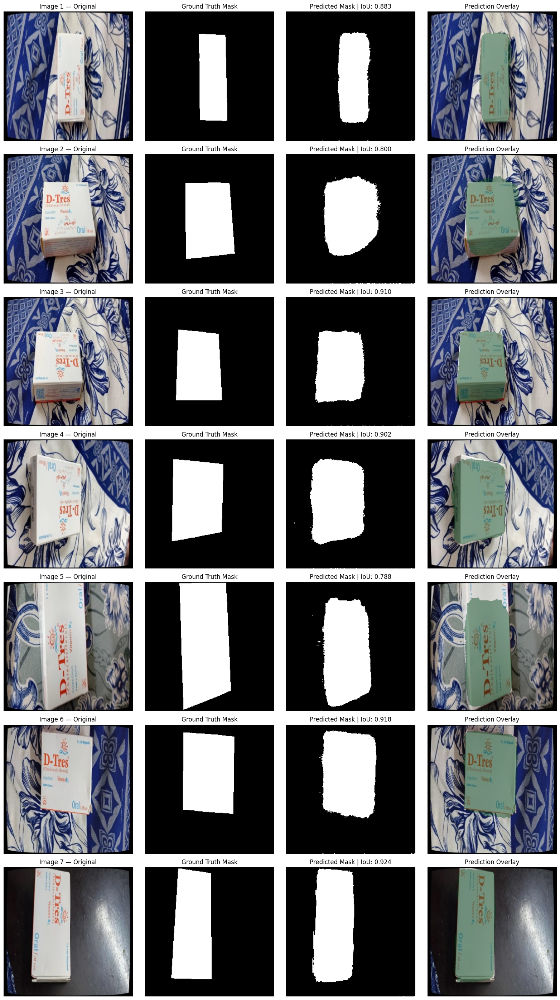

TEST SEGMENTATION VISUALIZATION
Images visualized: 7
Figure saved: /content/drive/MyDrive/MeasureIt/results/test_segmentation_visualization.png
PASS: Test predictions visualized successfully!


In [33]:
# =====================================================
# CELL 33 — VISUALIZE TEST SEGMENTATION RESULTS
# =====================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import torch

RESULTS_DIR = "/content/drive/MyDrive/MeasureIt/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

model.eval()

# ImageNet normalization values used during training
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

results = []

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)

        logits = model(images)
        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).float()

        for i in range(images.shape[0]):

            # Original image (reverse normalization)
            img = images[i].cpu().permute(1, 2, 0).numpy()
            img = np.clip(img * std + mean, 0, 1)

            # Ground truth mask
            gt_mask = masks[i, 0].cpu().numpy()

            # Predicted mask
            pred_mask = predictions[i, 0].cpu().numpy()

            # Calculate IoU
            gt_binary = gt_mask > 0.5
            pred_binary = pred_mask > 0.5

            intersection = np.logical_and(
                gt_binary, pred_binary
            ).sum()

            union = np.logical_or(
                gt_binary, pred_binary
            ).sum()

            iou = intersection / union if union > 0 else 1.0

            results.append(
                (img, gt_mask, pred_mask, iou)
            )


# -----------------------------------------------------
# DISPLAY ALL 7 TEST IMAGES
# -----------------------------------------------------

fig, axes = plt.subplots(
    len(results),
    4,
    figsize=(16, 4 * len(results))
)

for idx, (img, gt, pred, iou) in enumerate(results):

    # Original image
    axes[idx, 0].imshow(img)
    axes[idx, 0].set_title(f"Image {idx + 1} — Original")

    # Ground truth mask
    axes[idx, 1].imshow(gt, cmap="gray", vmin=0, vmax=1)
    axes[idx, 1].set_title("Ground Truth Mask")

    # Predicted mask
    axes[idx, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
    axes[idx, 2].set_title(
        f"Predicted Mask | IoU: {iou:.3f}"
    )

    # Predicted overlay
    axes[idx, 3].imshow(img)
    axes[idx, 3].imshow(
        np.ma.masked_where(pred <= 0.5, pred),
        cmap="Greens",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    axes[idx, 3].set_title("Prediction Overlay")

    for col in range(4):
        axes[idx, col].axis("off")

plt.tight_layout()

# Save the figure to Google Drive
save_path = os.path.join(
    RESULTS_DIR,
    "test_segmentation_visualization.png"
)

plt.savefig(
    save_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("=" * 55)
print("TEST SEGMENTATION VISUALIZATION")
print("=" * 55)
print("Images visualized:", len(results))
print("Figure saved:", save_path)
print("PASS: Test predictions visualized successfully!")